**ETAPA 1**

In [1]:
import pandas as pd

df = pd.read_csv("../data/raw/listings.csv.gz")

print("Forma:", df.shape)

print(list(df.columns))

Forma: (24876, 90)
['id', 'listing_url', 'scrape_id', 'last_scraped', 'source', 'name', 'description', 'neighborhood_overview', 'picture_url', 'host_id', 'host_url', 'host_profile_id', 'host_profile_url', 'host_name', 'host_since', 'hosts_time_as_user_years', 'hosts_time_as_user_months', 'hosts_time_as_host_years', 'hosts_time_as_host_months', 'host_location', 'host_about', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_is_superhost', 'host_thumbnail_url', 'host_picture_url', 'host_neighbourhood', 'host_listings_count', 'host_total_listings_count', 'host_verifications', 'host_has_profile_pic', 'host_identity_verified', 'neighbourhood', 'neighbourhood_cleansed', 'neighbourhood_group_cleansed', 'latitude', 'longitude', 'property_type', 'room_type', 'accommodates', 'bathrooms', 'bathrooms_text', 'bedrooms', 'beds', 'amenities', 'price', 'price_quote_checkin_date', 'price_quote_checkout_date', 'price_quote_total_price', 'price_quote_price_per_night', 'price_quote

In [2]:
# 4) Resumo técnico: nome, quantos valores não-vazios, e tipo de cada coluna
#    (object = texto, int64 = inteiro, float64 = decimal)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 24876 entries, 0 to 24875
Data columns (total 90 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            24876 non-null  int64  
 1   listing_url                                   24876 non-null  str    
 2   scrape_id                                     24876 non-null  int64  
 3   last_scraped                                  24876 non-null  str    
 4   source                                        24876 non-null  str    
 5   name                                          24876 non-null  str    
 6   description                                   24263 non-null  str    
 7   neighborhood_overview                         0 non-null      float64
 8   picture_url                                   24862 non-null  str    
 9   host_id                                       24876 non-null  int64  
 1

In [3]:
# 5) Percentagem de valores em falta por coluna, das piores para as melhores
#    isnull() marca cada célula vazia, mean() calcula a fração, *100 passa a %
faltas = df.isnull().mean() * 100
print(faltas.sort_values(ascending=False).head(50))

neighborhood_overview          100.000000
host_since                     100.000000
host_response_time             100.000000
host_thumbnail_url             100.000000
host_acceptance_rate           100.000000
host_response_rate             100.000000
host_verifications             100.000000
neighbourhood                  100.000000
host_total_listings_count      100.000000
host_neighbourhood             100.000000
calendar_updated               100.000000
instant_bookable               100.000000
host_about                      44.609262
host_location                   29.976684
bedrooms                        17.920888
bathrooms                       14.934073
review_scores_location          12.506030
review_scores_accuracy          12.502010
last_review                     12.502010
review_scores_rating            12.502010
review_scores_cleanliness       12.502010
review_scores_checkin           12.502010
first_review                    12.502010
reviews_per_month               12

In [4]:
colunas_uteis = [
    "price", "room_type", "property_type", "neighbourhood_cleansed",
    "latitude", "longitude", "accommodates", "bedrooms", "beds",
    "bathrooms", "bathrooms_text", "amenities", "minimum_nights",
    "host_is_superhost", "number_of_reviews", "review_scores_rating",
    "availability_365",
]

# Verifica se alguma não existe no ficheiro
em_falta = [c for c in colunas_uteis if c not in df.columns]
print("Colunas que não foram encontradas:", em_falta)

# Cria uma tabela mais pequena, só com as colunas escolhidas
# .copy() faz uma cópia independente, para não mexermos no original por engano
dados = df[colunas_uteis].copy()

print(dados.shape)
print(dados.dtypes)
print(dados.head())

Colunas que não foram encontradas: []
(24876, 17)
price                         str
room_type                     str
property_type                 str
neighbourhood_cleansed        str
latitude                  float64
longitude                 float64
accommodates                int64
bedrooms                  float64
beds                      float64
bathrooms                 float64
bathrooms_text                str
amenities                     str
minimum_nights            float64
host_is_superhost             str
number_of_reviews           int64
review_scores_rating      float64
availability_365            int64
dtype: object
       price        room_type       property_type neighbourhood_cleansed  \
0     $90.67  Entire home/apt  Entire rental unit                   Belm   
1    $108.98  Entire home/apt        Entire condo      Santa Maria Maior   
2    $122.00  Entire home/apt  Entire rental unit      Santa Maria Maior   
3  $1,096.00  Entire home/apt  Entire rental unit     

In [5]:
print(df["neighbourhood_cleansed"].nunique())  # nº de bairros distintos
print(df["property_type"].nunique())           # nº de tipos de propriedade

129
89


**ETAPA 2 - LIMPAR PREÇO**

In [6]:
# Tipo da coluna: object = texto, float64 = número
print(dados["price"].dtype)

# Primeiras linhas, para ver o formato
print(dados["price"].head())

str
0       $90.67
1      $108.98
2      $122.00
3    $1,096.00
4      $119.83
Name: price, dtype: str


In [7]:
# Tira o "$" e a "," (ex.: "$1,200.00" -> "1200.00")
# regex=False diz que estamos a trocar texto simples, não um padrão
dados["price"] = dados["price"].str.replace("$", "", regex=False)
dados["price"] = dados["price"].str.replace(",", "", regex=False)

# Converte para número. errors="coerce" transforma o que não der em NaN
# (NaN = "valor em falta") em vez de dar erro
dados["price"] = pd.to_numeric(dados["price"], errors="coerce")

In [8]:
# Quantos anúncios temos antes
print("Antes:", len(dados))

# dropna remove linhas com NaN; subset diz em que coluna olhar
dados = dados.dropna(subset=["price"])

# Quantos temos depois
print("Depois:", len(dados))

# Há preços iguais ou abaixo de zero? (não faz sentido ter)
print("Preços <= 0:", (dados["price"] <= 0).sum())

Antes: 24876
Depois: 22636
Preços <= 0: 0


In [9]:
# Resumo estatístico, com alguns percentis extra
# (percentil 99 = valor abaixo do qual estão 99% dos anúncios)
print(dados["price"].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]))

# Assimetria: perto de 0 = simétrico; muito positivo = cauda para a direita
print("Assimetria:", dados["price"].skew())

count    22636.000000
mean       189.788905
std        378.989017
min          3.670000
1%          29.000000
5%          46.790000
25%         92.000000
50%        136.000000
75%        200.000000
95%        442.062500
99%       1027.112000
max      16077.500000
Name: price, dtype: float64
Assimetria: 22.42672233433727


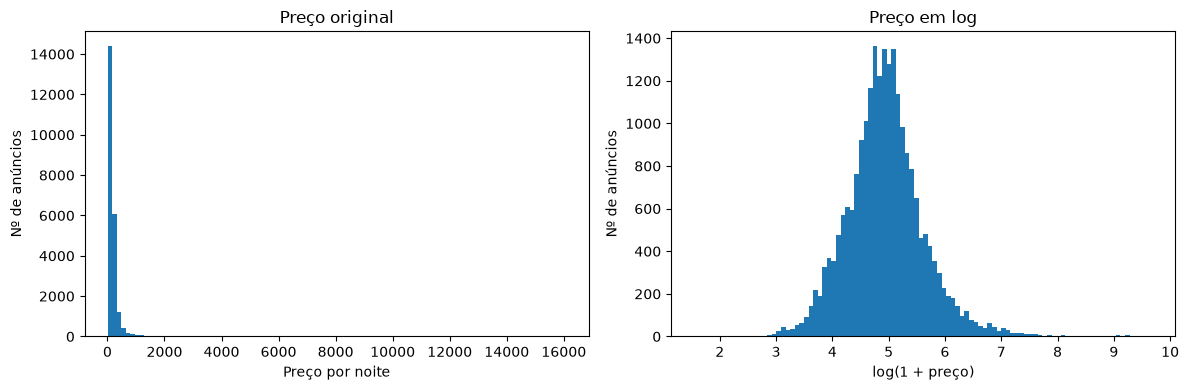

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# log1p = log(1 + preço). O "+1" evita problemas se houver preço 0
dados["log_price"] = np.log1p(dados["price"])

# Duas figuras lado a lado
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))

# Esquerda: preço original
eixos[0].hist(dados["price"], bins=100)
eixos[0].set_title("Preço original")
eixos[0].set_xlabel("Preço por noite")
eixos[0].set_ylabel("Nº de anúncios")

# Direita: preço em log
eixos[1].hist(dados["log_price"], bins=100)
eixos[1].set_title("Preço em log")
eixos[1].set_xlabel("log(1 + preço)")
eixos[1].set_ylabel("Nº de anúncios")

plt.tight_layout()
plt.savefig("../figures/etapa2_distribuicao_preco.png", dpi=150)
plt.show()

**Etapa 3 – Valores em falta**

In [11]:
# Percentagem de valores em falta por coluna, da maior para a menor
faltas = dados.isnull().mean() * 100
print(faltas.sort_values(ascending=False).round(2))

bedrooms                  17.29
review_scores_rating      11.85
bathrooms                  8.64
beds                       3.40
host_is_superhost          0.09
bathrooms_text             0.06
minimum_nights             0.00
price                      0.00
room_type                  0.00
property_type              0.00
accommodates               0.00
neighbourhood_cleansed     0.00
latitude                   0.00
longitude                  0.00
amenities                  0.00
number_of_reviews          0.00
availability_365           0.00
log_price                  0.00
dtype: float64


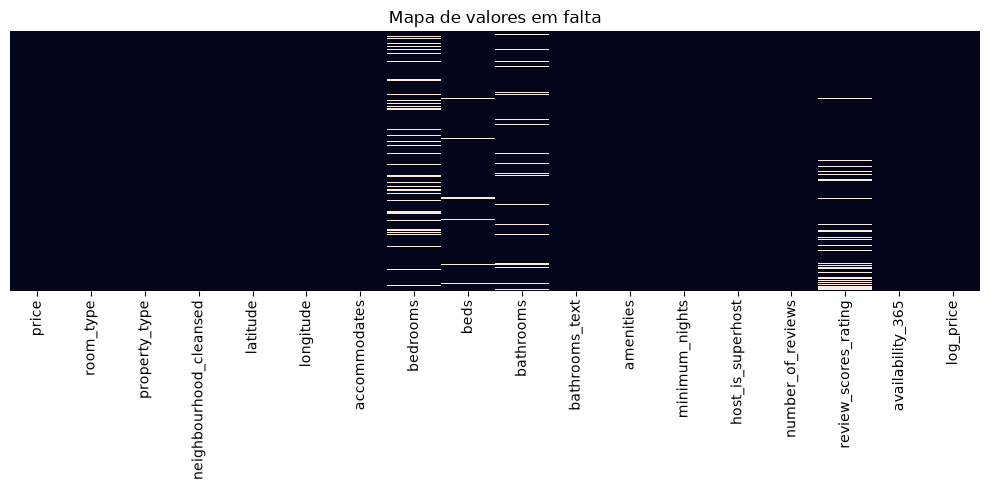

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

# Cada linha do gráfico é um anúncio, cada coluna uma variável
# isnull() devolve True onde falta valor; a cor mostra onde estão os buracos
plt.figure(figsize=(10, 5))
sns.heatmap(dados.isnull(), cbar=False, yticklabels=False)
plt.title("Mapa de valores em falta")
plt.tight_layout()
plt.savefig("../figures/etapa3_mapa_faltas.png", dpi=150)
plt.show()

In [13]:
# Anúncios sem nenhuma review
sem_reviews = dados["number_of_reviews"] == 0

# Anúncios sem nota média
sem_nota = dados["review_scores_rating"].isnull()

print("Sem reviews:", sem_reviews.sum())
print("Sem nota:", sem_nota.sum())
# Quantos estão nas duas situações ao mesmo tempo?
print("Os dois:", (sem_reviews & sem_nota).sum())

Sem reviews: 2683
Sem nota: 2683
Os dois: 2683


In [14]:
# Exemplos do texto (ex.: "1 bath", "1.5 baths", "Half-bath")
print(dados["bathrooms_text"].value_counts().head(10))

# Extrai o primeiro número do texto (ex.: "1.5 baths" -> 1.5)
numero = dados["bathrooms_text"].str.extract(r"(\d+\.?\d*)")[0].astype(float)

# Onde o texto diz "half" e não há número, usamos 0.5
meio = dados["bathrooms_text"].str.contains("half", case=False, na=False)
numero = numero.fillna(0.5 * meio.astype(float).where(meio))

# Onde as duas colunas existem, concordam?
ambas = dados["bathrooms"].notnull() & numero.notnull()
print("Concordam:", (dados.loc[ambas, "bathrooms"] == numero[ambas]).mean())

# Quantos buracos de bathrooms conseguiríamos preencher?
buracos = dados["bathrooms"].isnull()
print("Buracos recuperáveis:", (buracos & numero.notnull()).sum(), "de", buracos.sum())

bathrooms_text
1 bath            11422
2 baths            3191
1 private bath     1816
1 shared bath      1417
2 shared baths      942
3 baths             684
1.5 baths           677
2.5 baths           513
3 shared baths      298
0 baths             254
Name: count, dtype: int64
Concordam: 0.9987426250120901
Buracos recuperáveis: 1945 de 1955


In [15]:
# Mediana de quartos para cada capacidade (accommodates)
print(dados.groupby("accommodates")["bedrooms"].median().head(10))

# Mediana global, para comparar
print("Global:", dados["bedrooms"].median())

accommodates
1     1.0
2     1.0
3     1.0
4     2.0
5     2.0
6     3.0
7     3.0
8     4.0
9     4.0
10    4.0
Name: bedrooms, dtype: float64
Global: 1.0


In [16]:
copia = dados.copy()

# Política 1: simples (mediana global)
quartos_simples = copia["bedrooms"].fillna(copia["bedrooms"].median())

# Política 2: por grupos (mediana dos anúncios com a mesma capacidade)
mediana_grupo = copia.groupby("accommodates")["bedrooms"].transform("median")
quartos_grupo = copia["bedrooms"].fillna(mediana_grupo)

# Ver os dois lado a lado, só nas linhas que tinham buraco
buracos = copia["bedrooms"].isnull()
print(quartos_simples[buracos].describe())
print(quartos_grupo[buracos].describe())

count    3913.0
mean        1.0
std         0.0
min         1.0
25%         1.0
50%         1.0
75%         1.0
max         1.0
Name: bedrooms, dtype: float64
count    3913.000000
mean        1.078968
std         0.351959
min         1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max         7.000000
Name: bedrooms, dtype: float64


In [17]:
# Quantas linhas têm um valor diferente nas duas políticas?
diferentes = (quartos_simples[buracos] != quartos_grupo[buracos]).sum()
print("Valores diferentes:", diferentes, "de", buracos.sum())

Valores diferentes: 245 de 3913


**Etapa 4 – Outliers**

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Critério 1: IQR
def limites_iqr(serie, k=1.5):
    q1 = serie.quantile(0.25)       # 25% dos valores ficam abaixo disto
    q3 = serie.quantile(0.75)       # 75% dos valores ficam abaixo disto
    iqr = q3 - q1                   # largura do "miolo"
    limite_baixo = q1 - k * iqr
    limite_alto = q3 + k * iqr
    return limite_baixo, limite_alto

# Critério 2: MAD (devolve True para os valores suspeitos)
def outliers_mad(serie, limite=3.5):
    mediana = serie.median()
    mad = (serie - mediana).abs().median()   # desvio típico à mediana
    if mad == 0:
        print("MAD = 0: critério não aplicável a esta variável")
        return pd.Series(False, index=serie.index)
    z_modificado = 0.6745 * (serie - mediana) / mad
    return z_modificado.abs() > limite

In [19]:
for coluna in ["log_price", "minimum_nights", "accommodates"]:
    serie = dados[coluna]
    baixo, alto = limites_iqr(serie)
    fora_iqr = (serie < baixo) | (serie > alto)
    fora_mad = outliers_mad(serie)

    print(coluna)
    print("  limites IQR:", round(baixo, 2), "a", round(alto, 2))
    print("  fora pelo IQR:", fora_iqr.sum())
    print("  fora pelo MAD:", fora_mad.sum())
    print("  fora pelos dois:", (fora_iqr & fora_mad).sum())

# Limite alto do IQR do log-preço, convertido para preço normal
_, alto_log = limites_iqr(dados["log_price"])
print("Limite alto em preço normal:", round(np.expm1(alto_log), 1))

log_price
  limites IQR: 3.38 a 6.46
  fora pelo IQR: 738
  fora pelo MAD: 256
  fora pelos dois: 256
minimum_nights
  limites IQR: -2.0 a 6.0
  fora pelo IQR: 1403
  fora pelo MAD: 1126
  fora pelos dois: 1126
accommodates
  limites IQR: -1.0 a 7.0
  fora pelo IQR: 1643
  fora pelo MAD: 179
  fora pelos dois: 179
Limite alto em preço normal: 637.7


In [20]:
cols = ["price", "room_type", "accommodates", "bedrooms", "minimum_nights"]

# Os 10 mais caros
print(dados.sort_values("price", ascending=False)[cols].head(10))

# Os 10 mais baratos
print(dados.sort_values("price")[cols].head(10))

# Percentis de minimum_nights e accommodates
print(dados[["minimum_nights", "accommodates"]].describe(percentiles=[0.01, 0.99, 0.999]))

          price        room_type  accommodates  bedrooms  minimum_nights
18767  16077.50  Entire home/apt             4       2.0             2.0
18764  14472.00  Entire home/apt             4       2.0             2.0
11851  13610.67  Entire home/apt            16      14.0             3.0
18755  12865.97  Entire home/apt             4       2.0             2.0
17997  10955.30  Entire home/apt             3       1.0             1.0
18771  10592.00  Entire home/apt             4       2.0             2.0
18779  10592.00  Entire home/apt             4       2.0             2.0
18769  10592.00  Entire home/apt             4       2.0             2.0
18879  10547.50  Entire home/apt             3       2.0             2.0
18947  10503.00  Entire home/apt             2       1.0             2.0
       price        room_type  accommodates  bedrooms  minimum_nights
9092    3.67  Entire home/apt             4       2.0           180.0
21782   3.70     Private room             1       3.0    

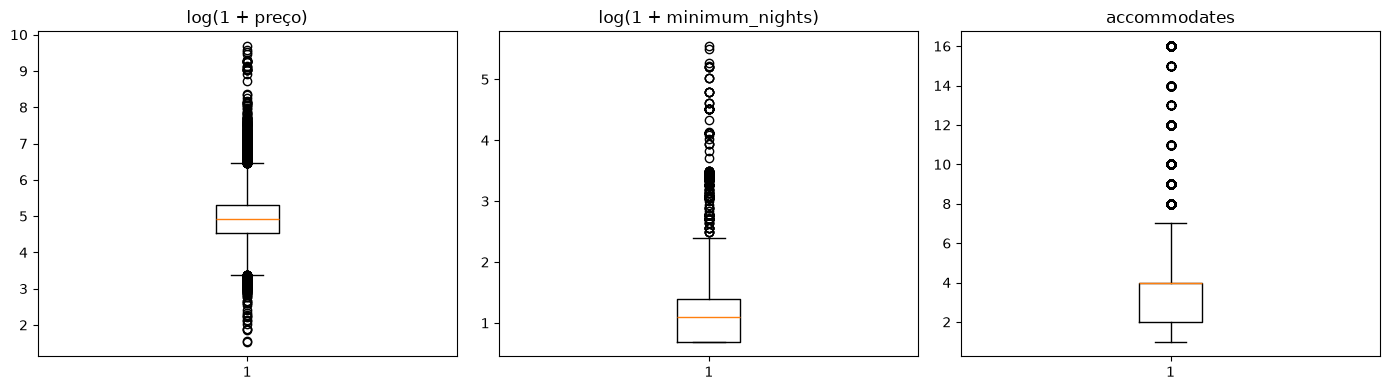

In [21]:
fig, eixos = plt.subplots(1, 3, figsize=(14, 4))

eixos[0].boxplot(dados["log_price"])
eixos[0].set_title("log(1 + preço)")

# minimum_nights em log para se conseguir ver
eixos[1].boxplot(np.log1p(dados["minimum_nights"].dropna()))
eixos[1].set_title("log(1 + minimum_nights)")

eixos[2].boxplot(dados["accommodates"])
eixos[2].set_title("accommodates")

plt.tight_layout()
plt.savefig("../figures/etapa4_outliers.png", dpi=150)
plt.show()

In [ ]:
import numpy as np, pandas as pd
import data_preparation as dp

df = dp.criar_features(dp.carregar_dados("../data/raw/listings.csv.gz"))

def criterios(serie, nome):
    s = serie.dropna()
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    por_iqr = (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)
    med = s.median(); mad = (s - med).abs().median()
    por_mad = ((0.6745 * (s - med) / mad).abs() > 3.5) if mad > 0 else pd.Series(False, index=s.index)
    p99 = s.quantile(0.99)
    return {"variável": nome, "n": len(s),
            "IQR (n)": int(por_iqr.sum()), "MAD z>3.5 (n)": int(por_mad.sum()),
            "ambos (n)": int((por_iqr & por_mad).sum()),
            "ambos (%)": round(100 * (por_iqr & por_mad).mean(), 2),
            "> p99 (n)": int((s > p99).sum()),
            "limite IQR": f"[{q1 - 1.5 * iqr:.2f}, {q3 + 1.5 * iqr:.2f}]"}

tab = pd.DataFrame([
    criterios(np.log1p(df["price"]), "log(1+preço)"),
    criterios(np.log1p(df["minimum_nights"]), "log(1+minimum_nights)"),
    criterios(df["accommodates"], "accommodates"),
])
print(tab.to_string(index=False))
tab.to_csv("../figures/outliers_criterios.csv", index=False)

# Regra de domínio para a estadia mínima (>30 noites = arrendamento mensal ou mais)
print("minimum_nights > 30:", int((df["minimum_nights"] > 30).sum()),
      f"({100 * (df['minimum_nights'] > 30).mean():.1f}%)")

In [22]:
copia = dados.copy()
baixo, alto = limites_iqr(copia["log_price"])
fora_iqr = (copia["log_price"] < baixo) | (copia["log_price"] > alto)
fora_mad = outliers_mad(copia["log_price"])

# Estratégia 1: nada
preco_nada = copia["price"]

# Estratégia 2: capping (limitar ao teto e ao chão do IQR)
preco_cap = np.expm1(copia["log_price"].clip(lower=baixo, upper=alto))

# Estratégia 3: filtrar (remover os suspeitos pelos DOIS critérios)
copia_filtrada = copia[~(fora_iqr & fora_mad)]
preco_filtrado = copia_filtrada["price"]

for nome, serie in [("Nada", preco_nada), ("Capping", preco_cap), ("Filtrar", preco_filtrado)]:
    print(nome, "| anúncios:", len(serie), "| máximo:", round(serie.max(), 1),
          "| média:", round(serie.mean(), 1), "| assimetria:", round(serie.skew(), 2))

Nada | anúncios: 22636 | máximo: 16077.5 | média: 189.8 | assimetria: 22.43
Capping | anúncios: 22636 | máximo: 637.7 | média: 169.4 | assimetria: 2.02
Filtrar | anúncios: 22380 | máximo: 1020.0 | média: 166.9 | assimetria: 2.65


In [23]:
baixo, alto = limites_iqr(dados["log_price"])
fora_preco = outliers_mad(dados["log_price"]) & (
    (dados["log_price"] < baixo) | (dados["log_price"] > alto)
)

mediana_log = dados["log_price"].median()
caros = fora_preco & (dados["log_price"] > mediana_log)
baratos = fora_preco & (dados["log_price"] <= mediana_log)

print("Caros:", caros.sum(), "| Baratos:", baratos.sum())
print("Baratos com minimum_nights > 30:", (baratos & (dados["minimum_nights"] > 30)).sum())

Caros: 229 | Baratos: 27
Baratos com minimum_nights > 30: 18


**Etapa 5: Feature engineering e codificação**

In [24]:
import json
import numpy as np
import pandas as pd

feat = dados.copy()

# --- Amenities: contar quantas existem (o texto é uma lista tipo ["Wifi", "Kitchen", ...]) ---
def contar_amenities(texto):
    try:
        return len(json.loads(texto))   # converte o texto em lista e conta
    except Exception:
        return np.nan                   # se o texto vier estragado

feat["n_amenities"] = feat["amenities"].apply(contar_amenities)
print(feat["n_amenities"].describe())
print("Sem contagem:", feat["n_amenities"].isnull().sum())

# --- Casas de banho: recuperar do texto (o que vimos na Etapa 3) ---
txt = feat["bathrooms_text"].str.lower()
num = txt.str.extract(r"(\d+\.?\d*)")[0].astype(float)          # primeiro número do texto
meia = txt.str.contains("half", na=False).map({True: 0.5, False: np.nan})
num = num.fillna(meia)                                           # "half-bath" -> 0.5
feat["bathrooms"] = feat["bathrooms"].fillna(num)                # só preenche onde faltava
print("bathrooms ainda em falta:", feat["bathrooms"].isnull().sum())

# --- Casa de banho partilhada? (0/1) ---
feat["banho_partilhado"] = txt.str.contains("shared", na=False).astype(int)

# --- Superhost: ver primeiro como vem escrito ---
print(feat["host_is_superhost"].value_counts(dropna=False))

count    22636.000000
mean        32.704762
std         14.696560
min          0.000000
25%         23.000000
50%         33.000000
75%         42.000000
max        100.000000
Name: n_amenities, dtype: float64
Sem contagem: 0
bathrooms ainda em falta: 10
host_is_superhost
f      15003
t       7613
NaN       20
Name: count, dtype: int64


In [25]:
# Superhost: "t" -> 1, "f" -> 0 (os poucos em falta ficam NaN por agora)
feat["superhost"] = feat["host_is_superhost"].map({"t": 1, "f": 0})

# Sem reviews (0/1): a ausência com significado da Etapa 3
feat["sem_reviews"] = (feat["number_of_reviews"] == 0).astype(int)

# number_of_reviews é muito assimétrica, por isso log
feat["log_reviews"] = np.log1p(feat["number_of_reviews"])

# minimum_nights limitado a 30 (regra de domínio da Etapa 4)
feat["min_noites"] = feat["minimum_nights"].clip(upper=30)

In [26]:
# Distância em km ao centro de Lisboa (fórmula haversine, distância sobre a esfera)
def distancia_centro_km(lat, lon):
    lat0, lon0 = np.radians(38.7075), np.radians(-9.1365)   # ~Praça do Comércio (confirma num mapa)
    lat, lon = np.radians(lat), np.radians(lon)
    a = np.sin((lat - lat0) / 2) ** 2 + np.cos(lat0) * np.cos(lat) * np.sin((lon - lon0) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

feat["dist_centro_km"] = distancia_centro_km(feat["latitude"], feat["longitude"])
print(feat["dist_centro_km"].describe())

count    22636.000000
mean        10.550281
std         14.762139
min          0.017751
25%          1.232107
50%          2.758923
75%         17.645146
max         66.902279
Name: dist_centro_km, dtype: float64


In [27]:
# neighbourhood_group_cleansed não está em "feat", vamos buscá-la ao df original
grupo = df.loc[feat.index, "neighbourhood_group_cleansed"]
print(grupo.value_counts().head(15))

# Quantos anúncios estão a mais de 15 km do centro?
print("Mais de 15 km:", (feat["dist_centro_km"] > 15).sum())

# Anúncios sem nenhuma comodidade
print("Sem amenities:", (feat["n_amenities"] == 0).sum())

neighbourhood_group_cleansed
Lisboa                   15575
Cascais                   2137
Sintra                    1491
Mafra                     1155
Lourinh                    496
Oeiras                     412
Torres Vedras              404
Loures                     287
Amadora                    251
Odivelas                   151
Alenquer                   102
Vila Franca De Xira         74
Cadaval                     54
Sobral De Monte Agrao       25
Arruda Dos Vinhos           12
Name: count, dtype: int64
Mais de 15 km: 6005
Sem amenities: 13


In [28]:
for coluna in ["room_type", "property_type", "neighbourhood_cleansed"]:
    contagem = feat[coluna].value_counts()
    print("\n", coluna, "-", len(contagem), "categorias")
    print(contagem.head(5))
    for n in [20, 50, 100, 200]:
        mantidas = (contagem >= n).sum()
        para_outros = contagem[contagem < n].sum()
        print(f"  mínimo {n}: ficam {mantidas} categorias; {para_outros} anúncios vão para 'Outros'")


 room_type - 4 categorias
room_type
Entire home/apt    16881
Private room        5464
Hotel room           150
Shared room          141
Name: count, dtype: int64
  mínimo 20: ficam 4 categorias; 0 anúncios vão para 'Outros'
  mínimo 50: ficam 4 categorias; 0 anúncios vão para 'Outros'
  mínimo 100: ficam 4 categorias; 0 anúncios vão para 'Outros'
  mínimo 200: ficam 2 categorias; 291 anúncios vão para 'Outros'

 property_type - 88 categorias
property_type
Entire rental unit             12858
Private room in rental unit     3326
Entire home                     1529
Entire condo                     596
Entire villa                     445
Name: count, dtype: int64
  mínimo 20: ficam 37 categorias; 297 anúncios vão para 'Outros'
  mínimo 50: ficam 25 categorias; 678 anúncios vão para 'Outros'
  mínimo 100: ficam 18 categorias; 1133 anúncios vão para 'Outros'
  mínimo 200: ficam 10 categorias; 2176 anúncios vão para 'Outros'

 neighbourhood_cleansed - 126 categorias
neighbourhood_cleansed

In [29]:
# Cada categoria vira uma coluna 0/1. drop_first=True tira uma (explico abaixo)
pd.get_dummies(feat["room_type"], prefix="room", drop_first=True, dtype=int)

,room_Hotel room,room_Private room,room_Shared room
0,0,0,0
1,0,0,0
2,0,0,0
3,0,0,0
4,0,0,0
...,...,...,...
24871,0,0,0
24872,0,1,0
24873,0,1,0
24874,0,1,0


In [30]:
media = feat["accommodates"].mean()
desvio = feat["accommodates"].std()
acc_escalado = (feat["accommodates"] - media) / desvio

print("média:", round(acc_escalado.mean(), 3), "| desvio:", round(acc_escalado.std(), 3))

média: 0.0 | desvio: 1.0


In [31]:
# Preço mediano por concelho (vê se Cascais/Mafra fogem à regra "longe = barato")
feat["concelho"] = df.loc[feat.index, "neighbourhood_group_cleansed"]
resumo = feat.groupby("concelho").agg(
    anuncios=("price", "count"),
    preco_mediano=("price", "median"),
    dist_mediana_km=("dist_centro_km", "median"),
)
print(resumo.sort_values("anuncios", ascending=False).head(10))

# A distância em log é menos assimétrica; correlação com o log-preço
feat["log_dist"] = np.log1p(feat["dist_centro_km"])
print(feat[["dist_centro_km", "log_dist", "log_price"]].corr()["log_price"])

               anuncios  preco_mediano  dist_mediana_km
concelho                                               
Lisboa            15575        132.000         1.632346
Cascais            2137        172.000        24.439006
Sintra             1491        139.500        24.935081
Mafra              1155        156.500        37.504649
Lourinh             496        149.500        62.418333
Oeiras              412        137.665        13.362265
Torres Vedras       404        124.065        51.561403
Loures              287         98.000        10.027720
Amadora             251         75.000         9.621037
Odivelas            151         80.490        10.350768
dist_centro_km    0.123500
log_dist          0.068616
log_price         1.000000
Name: log_price, dtype: float64


In [32]:
# Correlação dentro do concelho de Lisboa vs. fora
lisboa = feat[feat["concelho"] == "Lisboa"]
fora = feat[feat["concelho"] != "Lisboa"]
print("Dentro de Lisboa:", round(lisboa["dist_centro_km"].corr(lisboa["log_price"]), 3))
print("Fora de Lisboa:", round(fora["dist_centro_km"].corr(fora["log_price"]), 3))

Dentro de Lisboa: -0.173
Fora de Lisboa: 0.138


**Etapa 6: Split treino/validação/teste e k-fold, sem leakage**

In [33]:
from sklearn.model_selection import train_test_split, KFold

# 1º: separar o TESTE (20%) e guardá-lo. Não se mexe até ao fim.
# stratify=room_type garante a mesma proporção de tipos de quarto em cada parte
# (há só ~150 quartos de hotel e ~140 partilhados, convém não os perder todos num lado)
dev, teste = train_test_split(
    feat, test_size=0.20, random_state=42, stratify=feat["room_type"]
)

# 2º: do resto (80%), tirar a VALIDAÇÃO (25% de 80% = 20% do total)
treino, validacao = train_test_split(
    dev, test_size=0.25, random_state=42, stratify=dev["room_type"]
)

print("treino:", len(treino), "| validação:", len(validacao), "| teste:", len(teste))

# As proporções de room_type devem ser quase iguais nas três partes
for nome, parte in [("treino", treino), ("validação", validacao), ("teste", teste)]:
    print(nome, parte["room_type"].value_counts(normalize=True).round(3).to_dict())

treino: 13581 | validação: 4527 | teste: 4528
treino {'Entire home/apt': 0.746, 'Private room': 0.241, 'Hotel room': 0.007, 'Shared room': 0.006}
validação {'Entire home/apt': 0.746, 'Private room': 0.241, 'Hotel room': 0.007, 'Shared room': 0.006}
teste {'Entire home/apt': 0.746, 'Private room': 0.241, 'Hotel room': 0.007, 'Shared room': 0.006}


In [34]:
# CERTO: a mediana vem do TREINO e aplica-se também à validação e ao teste
mediana_quartos = treino["bedrooms"].median()
treino_q = treino["bedrooms"].fillna(mediana_quartos)
validacao_q = validacao["bedrooms"].fillna(mediana_quartos)   # NÃO recalcular aqui!

# Versão por grupos: mediana por capacidade, também só do treino
med_grupo = treino.groupby("accommodates")["bedrooms"].median()

def imputar_quartos_grupo(tabela):
    preenchimento = tabela["accommodates"].map(med_grupo)                    # mediana do grupo
    preenchimento = preenchimento.fillna(treino["bedrooms"].median())        # se o grupo não existir no treino
    return tabela["bedrooms"].fillna(preenchimento)

validacao_q_grupo = imputar_quartos_grupo(validacao)
print("Em falta na validação depois:", validacao_q_grupo.isnull().sum())

Em falta na validação depois: 0


In [35]:
media_t = treino["accommodates"].mean()
desvio_t = treino["accommodates"].std()

treino_esc = (treino["accommodates"] - media_t) / desvio_t
val_esc = (validacao["accommodates"] - media_t) / desvio_t   # usa a média/desvio do TREINO

print("treino:", round(treino_esc.mean(), 3), round(treino_esc.std(), 3))
print("validação:", round(val_esc.mean(), 3), round(val_esc.std(), 3))

treino: 0.0 1.0
validação: -0.024 0.986


In [36]:
# Limites do IQR calculados no treino (função da Etapa 4)
baixo, alto = limites_iqr(treino["log_price"])
print("Limites do treino:", round(baixo, 2), "a", round(alto, 2))

# Categorias com pelo menos 50 anúncios NO TREINO
contagem = treino["neighbourhood_cleansed"].value_counts()
frequentes = contagem[contagem >= 50].index

def agrupar_bairro(serie):
    # o que não estiver na lista de frequentes passa a "Outros"
    return serie.where(serie.isin(frequentes), "Outros")

bairro_treino = agrupar_bairro(treino["neighbourhood_cleansed"])
bairro_val = agrupar_bairro(validacao["neighbourhood_cleansed"])
print("Categorias no treino:", bairro_treino.nunique(), "| na validação:", bairro_val.nunique())

Limites do treino: 3.36 a 6.47
Categorias no treino: 37 | na validação: 37


In [37]:
# dev = treino + validação (80%). O teste fica de fora.
kf = KFold(n_splits=5, shuffle=True, random_state=42)

for i, (idx_tr, idx_va) in enumerate(kf.split(dev), start=1):
    tr = dev.iloc[idx_tr]      # 4 partes: treino deste fold
    va = dev.iloc[idx_va]      # 1 parte: validação deste fold

    # Em CADA fold, as medianas/médias/limites aprendem-se só com "tr"
    mediana_fold = tr["bedrooms"].median()

    print(f"Fold {i}: treino={len(tr)}, validação={len(va)}, mediana de quartos no treino={mediana_fold}")

Fold 1: treino=14486, validação=3622, mediana de quartos no treino=1.0
Fold 2: treino=14486, validação=3622, mediana de quartos no treino=1.0
Fold 3: treino=14486, validação=3622, mediana de quartos no treino=1.0
Fold 4: treino=14487, validação=3621, mediana de quartos no treino=1.0
Fold 5: treino=14487, validação=3621, mediana de quartos no treino=1.0


In [38]:
import sys
sys.path.append("../src")
import data_preparation as dp

r = dp.preparar_tudo("simples", "nada", guardar=False)
colunas = r["X_treino"].columns
print("property_type:", sum(c.startswith("property_type=") for c in colunas))
print("neighbourhood:", sum(c.startswith("neighbourhood_cleansed=") for c in colunas))

property_type: 19
neighbourhood: 36


**Etapa 8: regressão linear de raiz com gradient descent**

convergiu: True | divergiu: False | épocas: 2265
dif. pesos vs sklearn: 0.14247891790372041


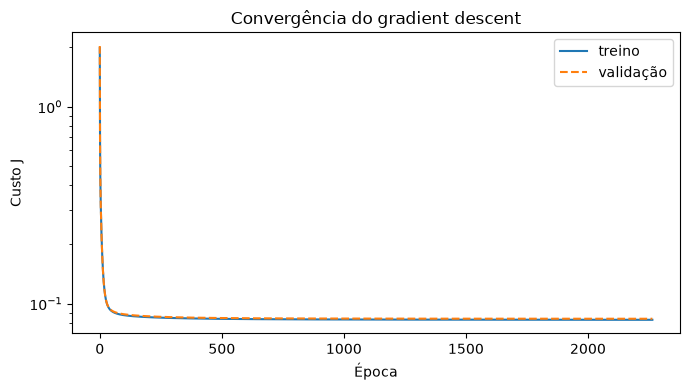

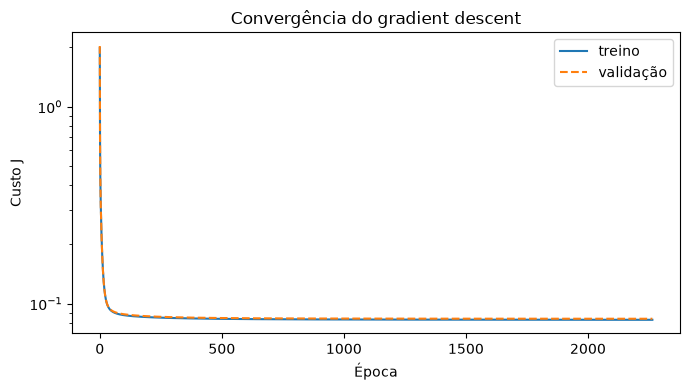

In [41]:
import sys
sys.path.append("../src")
import numpy as np
import data_preparation as dp
import linear_regression as lr
from sklearn.linear_model import LinearRegression

# Dados já preparados (imputação simples, sem tratar outliers)
r = dp.preparar_tudo("simples", "nada", guardar=False)

X_treino, y_treino = r["X_treino"].values, r["log_treino"].values
X_val,    y_val    = r["X_val"].values,    r["log_val"].values

# Treinar (batch). Se não convergir nas épocas dadas, aumenta a taxa ou as épocas
modelo = lr.RegressaoLinearGD(taxa=0.5, n_epocas=10000, tolerancia=1e-7, paciencia=20)
modelo.fit(X_treino, y_treino, X_val, y_val)
print("convergiu:", modelo.convergiu, "| divergiu:", modelo.divergiu,
      "| épocas:", len(modelo.historico["custo_treino"]))
sk = LinearRegression().fit(X_treino, y_treino)
print("dif. pesos vs sklearn:", np.abs(modelo.w - sk.coef_).max())

# Gráfico de convergência (guarda para o relatório)
modelo.grafico_convergencia("../figures/etapa8_convergencia_batch.png")

In [42]:
# Métricas na validação, no preço REAL (voltando do log)
prev_val = np.expm1(modelo.prever(X_val))
print(lr.todas_metricas(r["preco_val"].values, prev_val))

{'MAE': 66.04817864314813, 'RMSE': 351.19096171412576, 'R2': 0.13497455134715597}


In [43]:
prev_log = modelo.prever(X_val)
print(lr.todas_metricas(y_val, prev_log))   # MAE, RMSE e R2 em log

{'MAE': 0.28530076095983836, 'RMSE': 0.40935744127578955, 'R2': 0.6427463865802447}


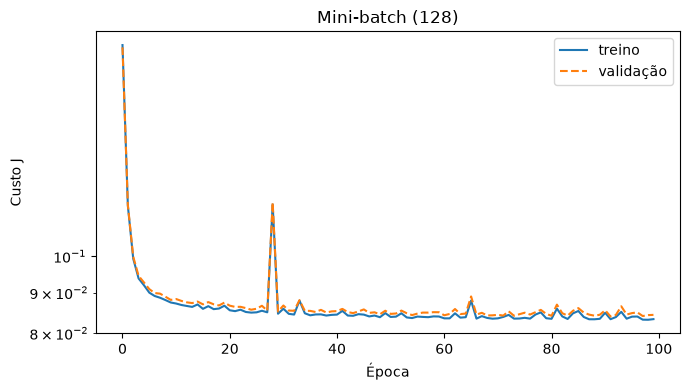

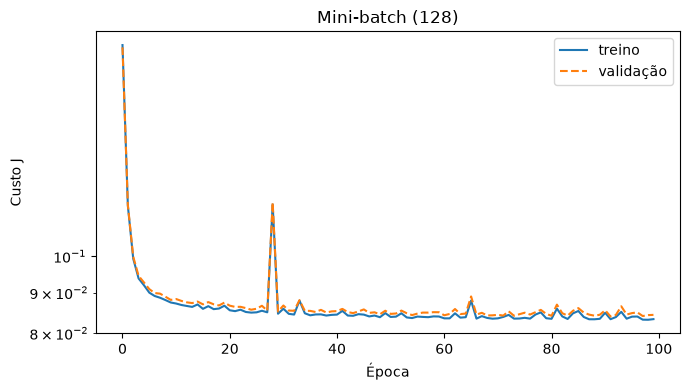

In [44]:
# Mini-batch (compara o gráfico com o do batch)
mini = lr.RegressaoLinearGD(taxa=0.05, n_epocas=100, tamanho_batch=128, tolerancia=0)
mini.fit(X_treino, y_treino, X_val, y_val)
mini.grafico_convergencia("../figures/etapa8_convergencia_minibatch.png", "Mini-batch (128)")

In [45]:
# L2: experimenta alguns lambdas e compara o erro na VALIDAÇÃO
for lam in [0, 1, 10, 100, 1000]:
    m = lr.RegressaoLinearGD(taxa=0.3, n_epocas=10000, lambda_l2=lam,
                             tolerancia=1e-12, paciencia=20).fit(X_treino, y_treino)
    p = np.expm1(m.prever(X_val))
    print(f"lambda={lam:5}: ", {k: round(v, 3) for k, v in lr.todas_metricas(r["preco_val"].values, p).items()})

lambda=    0:  {'MAE': 65.999, 'RMSE': 351.405, 'R2': 0.134}
lambda=    1:  {'MAE': 66.003, 'RMSE': 351.376, 'R2': 0.134}
lambda=   10:  {'MAE': 66.057, 'RMSE': 351.255, 'R2': 0.135}
lambda=  100:  {'MAE': 66.653, 'RMSE': 351.983, 'R2': 0.131}
lambda= 1000:  {'MAE': 68.862, 'RMSE': 357.5, 'R2': 0.104}


In [46]:
# Tabela de coeficientes (para a interpretação)
print(modelo.tabela_coeficientes(r["X_treino"].columns).head(10))

                               variavel      peso
0                 room_type=Shared room -0.896380
1          neighbourhood_cleansed=Beato -0.378160
2           property_type=Room in hotel  0.331688
3                      banho_partilhado -0.314714
4            property_type=Entire villa  0.306595
5  property_type=Room in boutique hotel  0.299399
6                    property_type=Boat -0.293086
7               property_type=Camper/RV -0.265219
8         neighbourhood_cleansed=Outros -0.256417
9                          accommodates  0.249362


In [47]:
tab = modelo.tabela_coeficientes(r["X_treino"].columns)
numericas = [c for c in tab["variavel"] if "=" not in c]
print(tab[tab["variavel"].isin(numericas)])

                variavel      peso
3       banho_partilhado -0.314714
9           accommodates  0.249362
33            min_noites -0.112805
34           log_reviews -0.110271
40             superhost  0.085748
44             bathrooms  0.074412
45              bedrooms  0.073559
50        dist_centro_km -0.063029
51           n_amenities  0.055429
53           sem_reviews  0.054480
60                  beds -0.035137
63  review_scores_rating  0.033428
65      availability_365  0.022668


**Etapa 9: interações, polinómios e preço bruto vs log**

In [ ]:
import sys
sys.path.append("../src")
import numpy as np
import pandas as pd
import data_preparation as dp
import linear_regression as lr


def experiencia(nome, extras=None, alvo="log", lam=0.0, imp="simples", out="nada"):
    """Treina um modelo e devolve as métricas na VALIDAÇÃO, sempre no preço real."""
    r = dp.preparar_tudo(imp, out, guardar=False, extras=extras)
    X_tr, X_va = r["X_treino"].values, r["X_val"].values

    if alvo == "log":
        y_tr = r["log_treino"].values
    else:
        # preço bruto: padronizamos o alvo (média/desvio do treino) para a descida do gradiente
        mu, sd = r["preco_treino"].values.mean(), r["preco_treino"].values.std()
        y_tr = (r["preco_treino"].values - mu) / sd

    # Se a taxa for grande demais (divergiu), dividimos por 3 e tentamos outra vez
    taxa = 0.5
    for tentativa in range(5):
        modelo = lr.RegressaoLinearGD(taxa=taxa, n_epocas=10000, lambda_l2=lam,
                                      tolerancia=1e-7, paciencia=20)
        modelo.fit(X_tr, y_tr)
        if not modelo.divergiu:
            break
        taxa = taxa / 3

    if alvo == "log":
        preco_prev = np.expm1(modelo.prever(X_va))
        r2_log_val = lr.r2(r["log_val"].values, modelo.prever(X_va))
        r2_log_tr = lr.r2(r["log_treino"].values, modelo.prever(X_tr))
    else:
        preco_prev = modelo.prever(X_va) * sd + mu
        r2_log_val, r2_log_tr = np.nan, np.nan

    met = lr.todas_metricas(r["preco_val"].values, preco_prev)
    return {
        "modelo": nome, "colunas": X_tr.shape[1],
        "MAE": round(met["MAE"], 2), "RMSE": round(met["RMSE"], 2), "R2_preco": round(met["R2"], 3),
        "R2_log_treino": round(r2_log_tr, 3), "R2_log_val": round(r2_log_val, 3),
        "preços<0": int((preco_prev < 0).sum()),
        "taxa": round(taxa, 4), "convergiu": modelo.convergiu, "divergiu": modelo.divergiu,
    }

In [49]:
linhas = [
    experiencia("1. Preço bruto", alvo="bruto"),
    experiencia("2. Log-preço (base)"),
    experiencia("3. + dist x Lisboa", ["dist_x_lisboa"]),
    experiencia("4. + capacidade x quarto privado", ["acc_x_privado"]),
    experiencia("5. + as duas interações", ["dist_x_lisboa", "acc_x_privado"]),
    experiencia("6. + polinómios grau 2", ["poly2"]),
    experiencia("7. + polinómios grau 3", ["poly3"]),
    experiencia("8. + grau 3, com L2 (lambda=100)", ["poly3"], lam=100),
    experiencia("9. + interações e grau 2", ["dist_x_lisboa", "acc_x_privado", "poly2"]),
]
tabela = pd.DataFrame(linhas)
pd.set_option("display.width", 250)
print(tabela.to_string(index=False))

                          modelo  colunas   MAE   RMSE  R2_preco  R2_log_treino  R2_log_val  preços<0   taxa  convergiu  divergiu
                  1. Preço bruto       71 92.81 344.60     0.167            NaN         NaN       228 0.5000       True     False
             2. Log-preço (base)       71 66.05 351.19     0.135          0.652       0.643         0 0.5000       True     False
              3. + dist x Lisboa       73 65.84 351.55     0.133          0.653       0.645         0 0.5000       True     False
4. + capacidade x quarto privado       72 66.91 365.31     0.064          0.652       0.643         0 0.5000       True     False
         5. + as duas interações       74 66.72 366.24     0.059          0.654       0.645         0 0.5000       True     False
          6. + polinómios grau 2       75 65.12 348.51     0.148          0.660       0.648         0 0.1667       True     False
          7. + polinómios grau 3       79 64.61 348.31     0.149          0.664       0.65

In [52]:
linhas2 = [
    experiencia("10. dist x Lisboa + grau 2", ["dist_x_lisboa", "poly2"]),
    experiencia("11. dist x Lisboa + grau 3", ["dist_x_lisboa", "poly3"]),
]
print(pd.DataFrame(linhas2).to_string(index=False))

# guarda a tabela para o relatório
pd.concat([tabela, pd.DataFrame(linhas2)]).to_csv("../figures/etapa9_tabela.csv", index=False)

                    modelo  colunas   MAE   RMSE  R2_preco  R2_log_treino  R2_log_val  preços<0   taxa  convergiu  divergiu
10. dist x Lisboa + grau 2       77 64.80 348.41     0.149          0.662       0.651         0 0.1667       True     False
11. dist x Lisboa + grau 3       81 64.59 348.36     0.149          0.664       0.652         0 0.1667       True     False


In [53]:
print(len(pd.read_csv("../figures/etapa9_tabela.csv")))

11


**Etapa 10 – Definir o alvo “caro”**

In [55]:
import importlib, data_preparation as dp
importlib.reload(dp)

r = dp.preparar_tudo("simples", "nada", guardar=False, caminho_dados="../data/raw/listings.csv.gz")
alvo = r["alvo_caro"]

# 1) Prevalência (% de caros) em cada conjunto
for nome in ["treino", "val", "teste"]:
    print(nome, round(r[f"y_{nome}_caro"].mean(), 3))

# 2) Limiares por grupo (room_type, concelho) e tamanho do grupo no treino
tr = r["treino"]
tamanhos = tr.groupby(["room_type", "concelho"]).size()
limiares = pd.Series(alvo.limiar_grupo, name="limiar_€")
print(pd.concat([tamanhos.rename("n_treino"), limiares], axis=1).sort_values("n_treino", ascending=False))
print("Limiares por room_type:", {k: round(v, 1) for k, v in alvo.limiar_tipo.items()})
print("Limiar global:", round(alvo.limiar_global, 1))

# 3) % de caros por room_type e por concelho (no treino)
tr_caro = r["y_treino_caro"]
print(tr_caro.groupby(tr["room_type"]).mean().round(3))
print(tr_caro.groupby(tr["concelho"]).mean().round(3))

# 4) Preço mediano: caro vs não caro
print(tr.groupby(tr_caro)["price"].median())

# 5) Comparar com a alternativa "bairro"
alt = dp.preparar_tudo("simples", "nada", guardar=False,
                       caminho_dados="../data/raw/listings.csv.gz", grupo_caro="bairro")
print("Concordância concelho vs bairro (val):",
      (r["y_val_caro"] == alt["y_val_caro"]).mean().round(3))

treino 0.2
val 0.197
teste 0.207
                                       n_treino  limiar_€
Entire home/apt Lisboa                     7045   229.404
Private room    Lisboa                     2212    93.000
Entire home/apt Cascais                     969   362.492
                Sintra                      622   421.400
                Mafra                       513   293.290
                Lourinh                     271   411.000
Private room    Cascais                     261   147.000
                Sintra                      250   137.200
Entire home/apt Torres Vedras               190   262.934
                Oeiras                      176   244.670
Private room    Mafra                       142   149.800
Entire home/apt Loures                      103   181.100
Private room    Amadora                      76    63.000
Entire home/apt Amadora                      76   169.000
Private room    Loures                       69    81.600
Hotel room      Lisboa                 

**Etapa 11 – Regressão logística de raiz**

convergiu: True | divergiu: False | épocas: 10715
convergiu: True | divergiu: False | épocas: 11128
sem pesos   accuracy=0.864 | % previstos caro=0.122 | log-loss val=0.332
balanceado  accuracy=0.802 | % previstos caro=0.307 | log-loss val=0.447
Baseline (dizer sempre 'não caro'): 0.803
                                             variavel      peso  odds_ratio
0                               room_type=Shared room  3.054896   21.218987
1                              room_type=Private room  2.979994   19.687697
2                        neighbourhood_cleansed=Beato -2.266853    0.103638
3   neighbourhood_cleansed=So Joo das Lampas e Ter... -2.175348    0.113569
4                         property_type=Room in hotel  2.168248    8.742952
5                                    banho_partilhado -1.969857    0.139477
6          neighbourhood_cleansed=So Domingos de Rana -1.893582    0.150532
7   neighbourhood_cleansed=Algs, Linda-a-Velha e C... -1.782625    0.168196
8                        nei

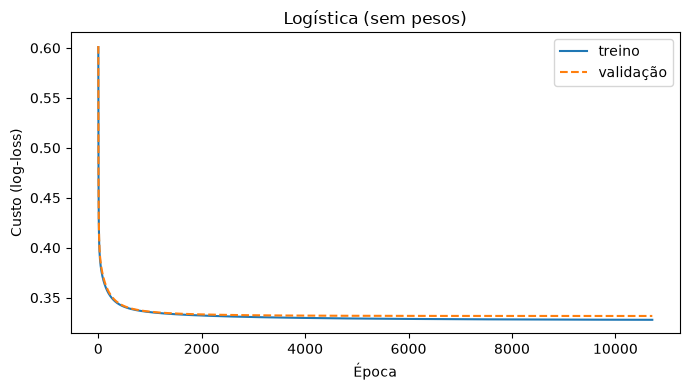

In [61]:
import importlib, data_preparation as dp, logistic_regression as lg
importlib.reload(dp); importlib.reload(lg)
import numpy as np, pandas as pd

r = dp.preparar_tudo("simples", "nada", guardar=False,
                     caminho_dados="../data/raw/listings.csv.gz")
X_tr, y_tr = r["X_treino"], r["y_treino_caro"]
X_va, y_va = r["X_val"], r["y_val_caro"]

# Segurança: o preço NÃO pode estar nas variáveis de entrada
assert "price" not in X_tr.columns and "log_price" not in X_tr.columns

# Modelo 1: sem pesos de classe
m1 = lg.RegressaoLogisticaGD(taxa=0.5, n_epocas=20000, tolerancia=1e-7)
m1.fit(X_tr, y_tr, X_va, y_va)
print("convergiu:", m1.convergiu, "| divergiu:", m1.divergiu,
      "| épocas:", len(m1.historico["custo_treino"]))

# Modelo 2: com pesos balanceados
m2 = lg.RegressaoLogisticaGD(taxa=0.5, n_epocas=20000, tolerancia=1e-7, peso_classe="balanceado")
m2.fit(X_tr, y_tr, X_va, y_va)
print("convergiu:", m2.convergiu, "| divergiu:", m2.divergiu,
      "| épocas:", len(m2.historico["custo_treino"]))

# Comparação rápida (a avaliação a sério é a Etapa 12)
for nome, m in [("sem pesos", m1), ("balanceado", m2)]:
    p = m.prever(X_va)
    print(f"{nome:11s} accuracy={lg.accuracy(y_va, p):.3f} | "
          f"% previstos caro={p.mean():.3f} | log-loss val={lg.log_loss(y_va, m.prever_proba(X_va)):.3f}")
print("Baseline (dizer sempre 'não caro'):", round(1 - y_va.mean(), 3))

# Gráfico de convergência
m1.grafico_convergencia("../figures/etapa11_convergencia.png", "Logística (sem pesos)")

# Coeficientes (odds ratio = e^peso)
print(m2.tabela_coeficientes(X_tr.columns).head(15))

In [62]:
import importlib, data_preparation as dp, logistic_regression as lg
importlib.reload(dp); importlib.reload(lg)
import numpy as np, pandas as pd

def auc(y, p):
    """ROC-AUC: prob. de um caro escolhido ao acaso ter score maior que um não caro."""
    y = np.asarray(y); p = np.asarray(p)
    ordem = pd.Series(p).rank().values          # ranks (empates tratados com média)
    n1 = y.sum(); n0 = len(y) - n1
    return (ordem[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

CAM = "../data/raw/listings.csv.gz"
cache = {}
def dados(imp="simples", extras=None):
    chave = (imp, tuple(extras) if extras else None)
    if chave not in cache:
        cache[chave] = dp.preparar_tudo(imp, "nada", guardar=False, caminho_dados=CAM, extras=extras)
    return cache[chave]

def exp(nome, imp="simples", extras=None, lam=0.0, pesos=None, taxa=0.5):
    r = dados(imp, extras)
    m = lg.RegressaoLogisticaGD(taxa=taxa, n_epocas=20000, tolerancia=1e-7,
                                lambda_l2=lam, peso_classe=pesos)
    m.fit(r["X_treino"], r["y_treino_caro"])
    pv = m.prever_proba(r["X_val"]); yv = r["y_val_caro"]
    return {"modelo": nome, "AUC val": round(auc(yv, pv), 4),
            "logloss val": round(lg.log_loss(yv, pv), 4),
            "acc val": round(lg.accuracy(yv, (pv >= 0.5).astype(int)), 4),
            "épocas": len(m.historico["custo_treino"]),
            "convergiu": m.convergiu, "divergiu": m.divergiu}

linhas = [
    exp("1 base (λ=0)"),
    exp("2 L2 λ=1",   lam=1),
    exp("3 L2 λ=10",  lam=10),
    exp("4 L2 λ=100", lam=100),
    exp("5 grupos + λ=10", imp="grupos", lam=10),
    exp("6 dist_x_lisboa + λ=10", extras=["dist_x_lisboa"], lam=10),
    exp("7 poly2 + λ=10",         extras=["poly2"], lam=10),
    exp("8 dist_x_lisboa+poly2 + λ=10", extras=["dist_x_lisboa", "poly2"], lam=10),
]
tabela11 = pd.DataFrame(linhas)
print(tabela11.to_string(index=False))
tabela11.to_csv("../figures/etapa11_tabela.csv", index=False)

                      modelo  AUC val  logloss val  acc val  épocas  convergiu  divergiu
                1 base (λ=0)   0.8686       0.3317   0.8639   10715       True     False
                    2 L2 λ=1   0.8686       0.3318   0.8648    8007       True     False
                   3 L2 λ=10   0.8668       0.3352   0.8613    3053       True     False
                  4 L2 λ=100   0.8514       0.3554   0.8491     677       True     False
             5 grupos + λ=10   0.8665       0.3357   0.8613    3041       True     False
      6 dist_x_lisboa + λ=10   0.8687       0.3329   0.8639    2786       True     False
              7 poly2 + λ=10   0.8696       0.3314   0.8630    2942       True     False
8 dist_x_lisboa+poly2 + λ=10   0.8706       0.3300   0.8644    2855       True     False


In [63]:
extra = ["dist_x_lisboa", "poly2"]
mais = pd.DataFrame([exp("8a extras λ=0", extras=extra, lam=0),
                     exp("8b extras λ=1", extras=extra, lam=1)])
print(mais.to_string(index=False))

       modelo  AUC val  logloss val  acc val  épocas  convergiu  divergiu
8a extras λ=0   0.8726       0.3276   0.8626    7656       True     False
8b extras λ=1   0.8725       0.3276   0.8635    6376       True     False


In [64]:
import importlib, data_preparation as dp, linear_regression as lin
importlib.reload(dp); importlib.reload(lin)
import numpy as np
from sklearn.linear_model import LinearRegression

r = dp.preparar_tudo("simples", "nada", guardar=False,
                     caminho_dados="../data/raw/listings.csv.gz",
                     extras=["dist_x_lisboa", "poly2"])

# O meu modelo (o mesmo do main.py)
m = lin.RegressaoLinearGD(taxa=0.1667, n_epocas=30000, tolerancia=1e-10)
m.fit(r["X_treino"], r["log_treino"], r["X_val"], r["log_val"])

# A solução "perfeita" (fórmula direta), para comparar
sk = LinearRegression().fit(r["X_treino"], r["log_treino"])

for nome, prev in [("meu GD", m.prever(r["X_val"])), ("exato (sklearn)", sk.predict(r["X_val"]))]:
    p = np.expm1(prev)
    print(nome, {k: round(v, 3) for k, v in lin.todas_metricas(r["preco_val"], p).items()},
          "| R2 log:", round(lin.r2(r["log_val"], prev), 4))

print("maior diferença nos pesos:", np.abs(m.w - sk.coef_).max().round(4))
print("custo nas últimas 3 épocas:", m.historico["custo_treino"][-3:])

meu GD {'MAE': 64.758, 'RMSE': 348.461, 'R2': 0.148} | R2 log: 0.6509
exato (sklearn) {'MAE': 64.75, 'RMSE': 348.479, 'R2': 0.148} | R2 log: 0.6509
maior diferença nos pesos: 0.0701
custo nas últimas 3 épocas: [0.08009145949660483, 0.08009145922446917, 0.08009145895234866]


**Etapa 12 – Métricas de classificação e limiar**

In [65]:
import importlib, data_preparation as dp, logistic_regression as lg
importlib.reload(dp); importlib.reload(lg)
import numpy as np, pandas as pd

r = dp.preparar_tudo("simples", "nada", guardar=False, caminho_dados="../data/raw/listings.csv.gz",
                     extras=["dist_x_lisboa", "poly2"])
y_va = r["y_val_caro"]

res = {}
for nome, pc in [("sem pesos", None), ("balanceado", "balanceado")]:
    m = lg.RegressaoLogisticaGD(taxa=0.5, n_epocas=20000, tolerancia=1e-7, peso_classe=pc)
    m.fit(r["X_treino"], r["y_treino_caro"])
    res[nome] = m.prever_proba(r["X_val"])
    print(nome, "| AUC:", round(lg.auc_roc(y_va, res[nome]), 3),
          "| PR-AUC:", round(lg.average_precision(y_va, res[nome]), 3))

print("prevalência (referência do PR-AUC):", round(y_va.mean(), 3))
print(lg.tabela_limiares(y_va, res["sem pesos"]).to_string(index=False))

# Limiar que maximiza o recall mantendo precision >= 0.60 (exemplo de "critério de negócio")
print(lg.melhor_limiar(y_va, res["sem pesos"], "recall", precision_minima=0.60))

sem pesos | AUC: 0.873 | PR-AUC: 0.689
balanceado | AUC: 0.874 | PR-AUC: 0.685
prevalência (referência do PR-AUC): 0.197
 limiar  precision  recall    F1  accuracy  % previstos caro
   0.10      0.379   0.904 0.534     0.690             0.469
   0.15      0.439   0.852 0.580     0.757             0.382
   0.20      0.491   0.793 0.606     0.797             0.318
   0.25      0.547   0.743 0.631     0.828             0.268
   0.30      0.574   0.663 0.615     0.837             0.228
   0.35      0.604   0.620 0.612     0.845             0.202
   0.40      0.647   0.571 0.606     0.854             0.174
   0.50      0.728   0.483 0.581     0.863             0.131
   0.60      0.792   0.415 0.545     0.863             0.103
   0.70      0.841   0.303 0.445     0.851             0.071
(0.35, 0.6199551569506726)
